In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Source: S. Prahl, "Optical absorption of hemoglobin", omlc.org
text = open("data/prahl_hemoglobin.html", encoding="latin-1").read()
text = re.sub(r"<[^>]+>", " ", text)  # remove HTML tags
rows = re.findall(r"^\s*(\d+)\s+([\d.]+)\s+([\d.]+)\s*$", text, flags=re.M)
data = np.array(rows, dtype=float)
lam, e_hbo2, e_hb = data[:, 0], data[:, 1], data[:, 2]  # nm, cm-1/M, cm-1/M

print(data.shape)
print(data[lam == 660])

(376, 3)
[[ 660.    319.6  3226.56]]


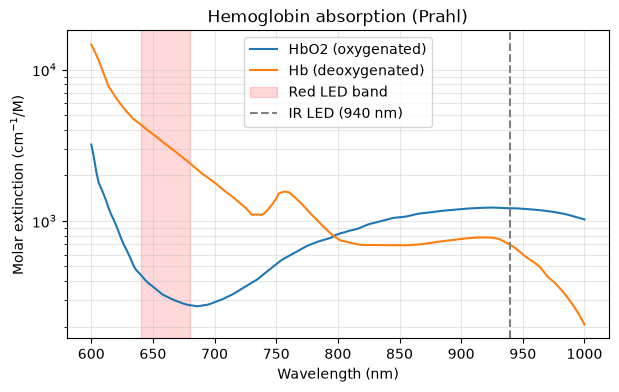

In [3]:
mask = (lam >= 600) & (lam <= 1000)
plt.figure(figsize=(7, 4))
plt.semilogy(lam[mask], e_hbo2[mask], label="HbO2 (oxygenated)")
plt.semilogy(lam[mask], e_hb[mask], label="Hb (deoxygenated)")
plt.axvspan(640, 680, color="red", alpha=0.15, label="Red LED band")
plt.axvline(940, color="gray", linestyle="--", label="IR LED (940 nm)")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Molar extinction (cm$^{-1}$/M)")
plt.title("Hemoglobin absorption (Prahl)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

In [4]:
def mua_melanin(lam_nm, f_mel):
    """Absorption coefficient of the epidermis (cm^-1), Jacques (2013).
    f_mel: volume fraction of melanosomes, about 0.02 (light skin) to 0.4 (very dark skin)."""
    return f_mel * 6.6e11 * lam_nm**-3.33

print("mu_a at 660 nm, f=0.3:", round(mua_melanin(660, 0.3), 1), "cm-1")
print("mu_a at 940 nm, f=0.3:", round(mua_melanin(940, 0.3), 1), "cm-1")

mu_a at 660 nm, f=0.3: 80.8 cm-1
mu_a at 940 nm, f=0.3: 24.9 cm-1


In [5]:
def led_spectrum(lam_nm, center, fwhm):
    """Gaussian emission spectrum, normalized so that its sum is 1."""
    s = np.exp(-4 * np.log(2) * (lam_nm - center)**2 / fwhm**2)
    return s / s.sum()

In [6]:
d_skin = 0.02  # cm: about 100 um of epidermis, crossed twice (in and out of the finger)

print("FWHM | shift of the red LED (nm) for f_mel = 0.02, 0.1, 0.2, 0.4")
for fwhm in [20, 30, 40]:
    led = led_spectrum(lam, 660, fwhm)
    shifts = []
    for f in [0.02, 0.1, 0.2, 0.4]:
        seen = led * np.exp(-mua_melanin(lam, f) * d_skin)  # Beer-Lambert through the skin
        center = (lam * seen).sum() / seen.sum()             # "center of gravity" of the light
        shifts.append(center - 660)
    print(fwhm, "nm |", "  ".join(f"{s:+.2f}" for s in shifts))

FWHM | shift of the red LED (nm) for f_mel = 0.02, 0.1, 0.2, 0.4
20 nm | +0.04  +0.20  +0.39  +0.78
30 nm | +0.09  +0.44  +0.88  +1.75
40 nm | +0.16  +0.79  +1.56  +3.10


In [7]:
C_HB = 150 / 64500  # hemoglobin concentration in blood (mol/L): 150 g/L / 64,500 g/mol

def mua_blood(S):
    """Absorption coefficient of blood (cm^-1) at saturation S (0 to 1)."""
    return 2.303 * C_HB * (S * e_hbo2 + (1 - S) * e_hb)

def ratio_R(S, f_mel, fwhm_red=20, d_skin=0.02, dd=0.002):
    """Ratio R measured by a virtual oximeter.
    dd: extra blood thickness at each heartbeat (cm)."""
    T_skin = np.exp(-mua_melanin(lam, f_mel) * d_skin)  # skin filter (constant)
    pulse = np.exp(-mua_blood(S) * dd)                  # extra absorption at the heartbeat
    def ac_dc(led):
        dc = (led * T_skin).sum()             # light received between beats
        peak = (led * T_skin * pulse).sum()   # light received at the beat
        return (dc - peak) / dc
    return ac_dc(led_spectrum(lam, 660, fwhm_red)) / ac_dc(led_spectrum(lam, 940, 40))

for S in [1.0, 0.97, 0.90, 0.85, 0.80, 0.70]:
    print(f"S = {S:.2f}  ->  R = {ratio_R(S, 0.02):.3f}")

S = 1.00  ->  R = 0.272
S = 0.97  ->  R = 0.350
S = 0.90  ->  R = 0.539
S = 0.85  ->  R = 0.682
S = 0.80  ->  R = 0.832
S = 0.70  ->  R = 1.154


In [8]:
S_cal = np.linspace(0.70, 1.00, 61)  # saturations used for calibration: 70 % to 100 %

def spo2_bias(S, f_mel, fwhm_red=20):
    """Displayed SpO2 minus true saturation (points), for an oximeter calibrated on light skin."""
    R_cal = np.array([ratio_R(s, 0.02, fwhm_red) for s in S_cal])  # calibration on light skin
    R = ratio_R(S, f_mel, fwhm_red)                                  # measurement on this patient
    displayed = 100 * np.interp(R, R_cal[::-1], S_cal[::-1])         # read the calibration curve
    return displayed - 100 * S

for fwhm in [20, 30, 40]:
    print(f"LED {fwhm} nm  (columns: f_mel = 0.02, 0.1, 0.2, 0.4)")
    for S in [0.97, 0.85]:
        print(f"  true SpO2 {100*S:.0f} %:", "  ".join(f"{spo2_bias(S, f, fwhm):+.2f}" for f in [0.02, 0.1, 0.2, 0.4]))

LED 20 nm  (columns: f_mel = 0.02, 0.1, 0.2, 0.4)
  true SpO2 97 %: +0.00  +0.02  +0.05  +0.11
  true SpO2 85 %: +0.00  +0.05  +0.10  +0.21
LED 30 nm  (columns: f_mel = 0.02, 0.1, 0.2, 0.4)
  true SpO2 97 %: +0.00  +0.06  +0.14  +0.29
  true SpO2 85 %: +0.00  +0.12  +0.26  +0.53
LED 40 nm  (columns: f_mel = 0.02, 0.1, 0.2, 0.4)
  true SpO2 97 %: +0.00  +0.15  +0.32  +0.64
  true SpO2 85 %: +0.00  +0.24  +0.53  +1.08


In [9]:
def ratio_R_liquid(mua_pulse, f_mel, fwhm_red=20, d_skin=0.02, dd=0.002):
    """Same as ratio_R, but the pulsed absorber is any liquid (array of mu_a)."""
    T_skin = np.exp(-mua_melanin(lam, f_mel) * d_skin)
    pulse = np.exp(-mua_pulse * dd)
    def ac_dc(led):
        dc = (led * T_skin).sum()
        return (dc - (led * T_skin * pulse).sum()) / dc
    return ac_dc(led_spectrum(lam, 660, fwhm_red)) / ac_dc(led_spectrum(lam, 940, 40))

def liquid_B(S):
    """Liquid with the spectral slope of hemoglobin (ideal case: blood itself)."""
    return mua_blood(S)

def liquid_A(S):
    """Flat liquid: same absorption as blood at 660 and 940 nm, but no slope inside each band."""
    mb = mua_blood(S)
    a660, a940 = mb[lam == 660][0], mb[lam == 940][0]
    return np.where(lam < 800, a660, a940)

def skin_effect(liquid, S, f_mel, fwhm_red=20):
    """Displayed SpO2 on dark skin minus displayed SpO2 on light skin (points)."""
    R_cal = np.array([ratio_R(s, 0.02, fwhm_red) for s in S_cal])
    def displayed(f):
        R = ratio_R_liquid(liquid(S), f, fwhm_red)
        return 100 * np.interp(R, R_cal[::-1], S_cal[::-1])
    return displayed(f_mel) - displayed(0.02)

for S in [0.97, 0.85]:
    for name, liquid in [("B", liquid_B), ("A", liquid_A)]:
        print(f"SpO2 {100*S:.0f} %, liquid {name}:",
              "  ".join(f"{skin_effect(liquid, S, f, 40):+.2f}" for f in [0.1, 0.2, 0.4]))

SpO2 97 %, liquid B: +0.15  +0.32  +0.64
SpO2 97 %, liquid A: -0.00  -0.00  -0.00
SpO2 85 %, liquid B: +0.24  +0.53  +1.08
SpO2 85 %, liquid A: -0.00  +0.00  -0.00


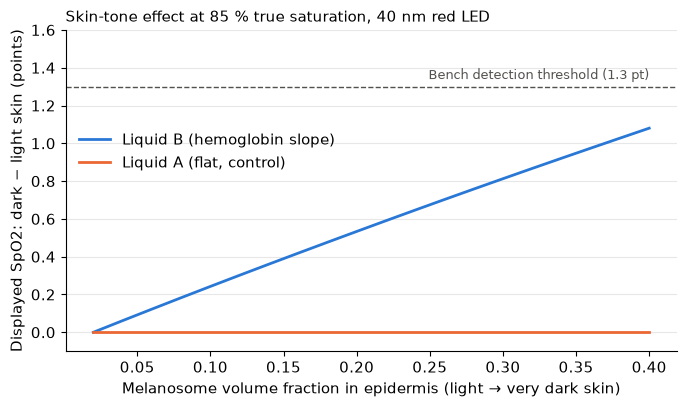

In [10]:
import os
os.makedirs("figures", exist_ok=True)  # folder for the saved images

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
THRESHOLD = 1.3  # minimum detectable A/B effect of the bench (dossier, part 5.2)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

f_values = np.linspace(0.02, 0.40, 20)
effect_B = [skin_effect(liquid_B, 0.85, f, 40) for f in f_values]
effect_A = [skin_effect(liquid_A, 0.85, f, 40) for f in f_values]

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(f_values, effect_B, color=BLUE, lw=2, label="Liquid B (hemoglobin slope)")
ax.plot(f_values, effect_A, color=ORANGE, lw=2, label="Liquid A (flat, control)")
ax.axhline(THRESHOLD, color=GREY, lw=1, ls="--")
ax.text(0.40, THRESHOLD + 0.04, "Bench detection threshold (1.3 pt)", color=GREY, fontsize=9, ha="right")
ax.set_xlabel("Melanosome volume fraction in epidermis (light → very dark skin)")
ax.set_ylabel("Displayed SpO2: dark − light skin (points)")
ax.set_title("Skin-tone effect at 85 % true saturation, 40 nm red LED", loc="left", fontsize=11)
ax.set_ylim(-0.1, 1.6)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(0, 0.62))
fig.tight_layout()
fig.savefig("figures/fig1_liquid_A_vs_B.png", dpi=150)
plt.show()

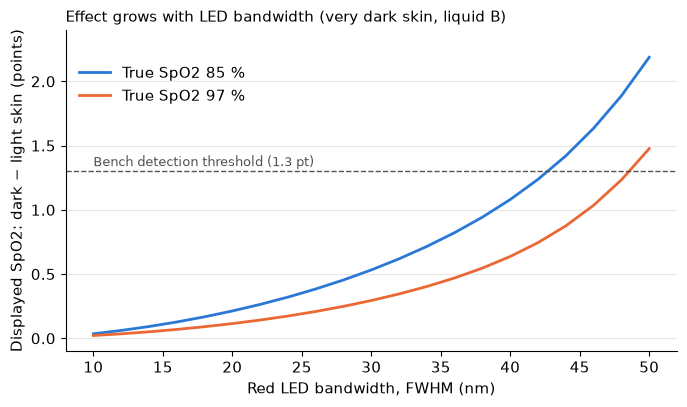

In [11]:
widths = np.arange(10, 51, 2)

fig, ax = plt.subplots(figsize=(7, 4.2))
for S, color in [(0.85, BLUE), (0.97, ORANGE)]:
    effect = [skin_effect(liquid_B, S, 0.4, w) for w in widths]
    ax.plot(widths, effect, color=color, lw=2, label=f"True SpO2 {100*S:.0f} %")
ax.axhline(THRESHOLD, color=GREY, lw=1, ls="--")
ax.text(10, THRESHOLD + 0.04, "Bench detection threshold (1.3 pt)", color=GREY, fontsize=9)
ax.set_xlabel("Red LED bandwidth, FWHM (nm)")
ax.set_ylabel("Displayed SpO2: dark − light skin (points)")
ax.set_title("Effect grows with LED bandwidth (very dark skin, liquid B)", loc="left", fontsize=11)
ax.set_ylim(-0.1, 2.4)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.93))
fig.tight_layout()
fig.savefig("figures/fig2_led_bandwidth.png", dpi=150)
plt.show()